# Hipótese 1: Padrões Temporais e Concentração de Anomalias Críticas (> 30s)

## 1. Contexto Teórico e Problematização
As Portas de Plataforma (PSDs) operam sob estresse eletromecânico contínuo. Para elevar o rigor da análise preditiva e eliminar qualquer interferência de obstruções operacionais rápidas de passageiros (eventos curtos de até 30 segundos resolvidos automaticamente ou por ciclo simples de recuo).

Anomalias cujo tempo de normalização excede 30 segundos representam episódios em que a porta ficou paralisada por meio minuto ou mais, indicando perda efetiva de torque do atuador, desarmamento de segurança, falha de comunicação lógica ou necessidade de intervenção do operador de trem/plataforma.

---

## 2. Definindo a Questão Investigada
* **H1.1 (Concentração de Anomalias Críticas nos Picos):** As anomalias de severidade elevada (> 30s), que possuem impacto direto na operação comercial e na integridade dos ativos, concentram-se fortemente nos períodos de maior demanda de transporte (pico matutino das 06h-09h e vespertino das 16h-19h).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

alarmes_path = "../../data/Informações de Manutenção - Motiva/Alarmes do sistema de PSD.xlsx"
df_alarmes = pd.read_excel(alarmes_path)

def parse_tempo(val):
    if pd.isna(val): return np.nan
    val_str = str(val).strip()
    try:
        if 'dias,' in val_str:
            dias_part, time_part = val_str.split('dias,')
            dias = int(dias_part.strip().split()[0])
        else:
            dias = 0
            time_part = val_str
        h, m, s = map(int, time_part.strip().split(':'))
        return dias * 86400 + h * 3600 + m * 60 + s
    except:
        return np.nan

df_alarmes['tempo_seg'] = df_alarmes['Tempo de Normalização'].apply(parse_tempo)
df_alarmes['DT_Alarme'] = pd.to_datetime(df_alarmes['Horário do Alarme'], errors='coerce')
df_alarmes['Hora'] = df_alarmes['DT_Alarme'].dt.hour

df_30s = df_alarmes[df_alarmes['tempo_seg'] > 30]

print(f"Total de Alarmes Registrados: {len(df_alarmes):,}")
print(f"Total de Anomalias Críticas (> 30s): {len(df_30s):,} ({len(df_30s)/len(df_alarmes)*100:.2f}%)")



Total de Alarmes Registrados: 150,003
Total de Anomalias Críticas (> 30s): 78,645 (52.43%)


## 3. Distribuição Horária das Anomalias Críticas (> 30s)

Visualização da distribuição das 78.645 anomalias críticas (> 30s) ao longo das 24 horas do dia, com as barras dos horários de pico (06h-09h e 16h-19h) destacadas em vermelho e os demais períodos em azul.


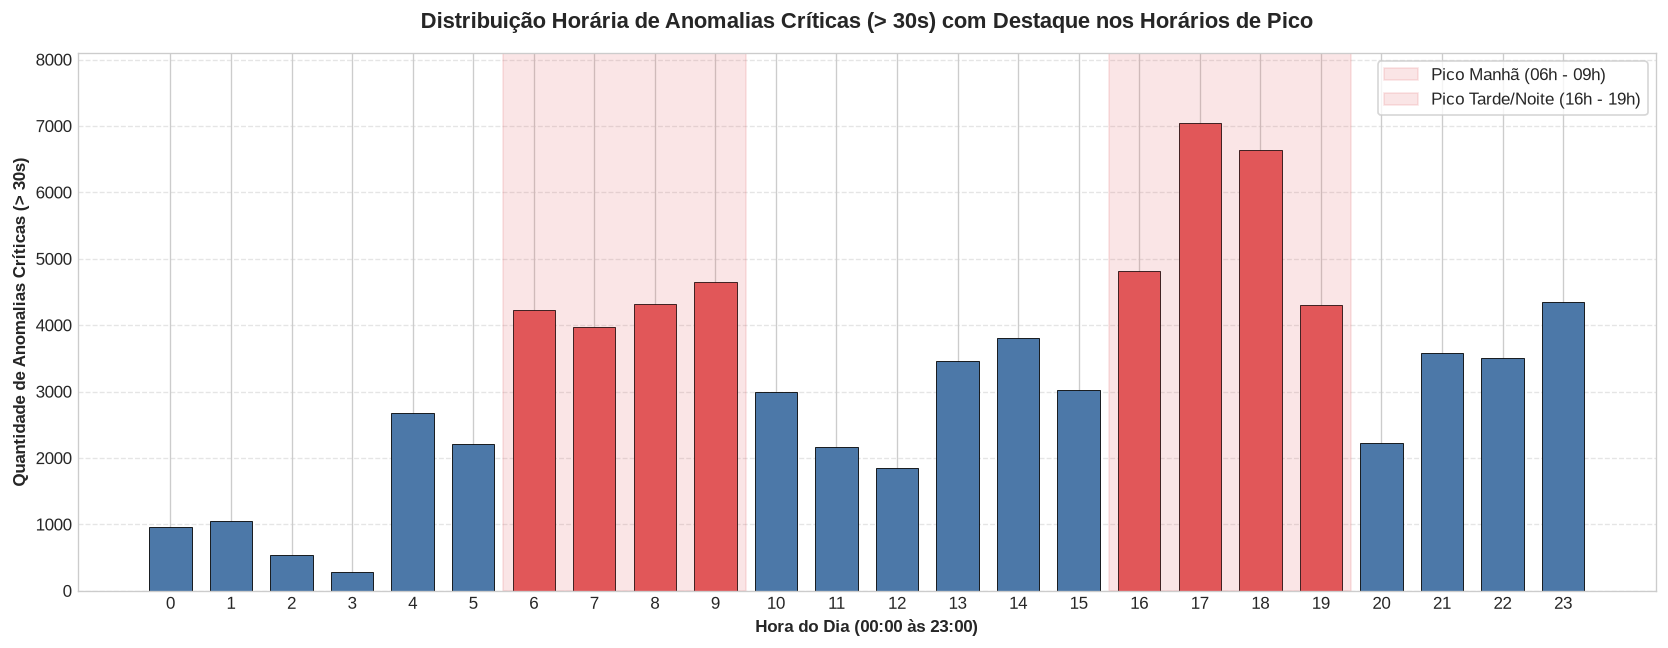

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5.5))

hora_counts = df_30s['Hora'].value_counts().sort_index().reset_index()
hora_counts.columns = ['Hora', 'Quantidade']

# Plotagem com destaque de cor
colors = []
for h in hora_counts['Hora']:
    if (6 <= h <= 9) or (16 <= h <= 19):
        colors.append('#e15759') 
    else:
        colors.append('#4c78a8') 

bars = ax.bar(hora_counts['Hora'], hora_counts['Quantidade'], color=colors, edgecolor='black', linewidth=0.5, width=0.7)

# Sombreamento das faixas de pico
ax.axvspan(5.5, 9.5, color='#e15759', alpha=0.15, label='Pico Manhã (06h - 09h)')
ax.axvspan(15.5, 19.5, color='#e15759', alpha=0.15, label='Pico Tarde/Noite (16h - 19h)')

ax.set_title('Distribuição Horária de Anomalias Críticas (> 30s) com Destaque nos Horários de Pico', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Hora do Dia (00:00 às 23:00)', fontsize=10, fontweight='bold')
ax.set_ylabel('Quantidade de Anomalias Críticas (> 30s)', fontsize=10, fontweight='bold')
ax.set_xticks(range(0, 24))
ax.set_ylim(0, max(hora_counts['Quantidade']) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()



## 4. Quantificação Estatística por Faixa Horária Operacional

Segmentação detalhada das anomalias críticas (> 30s) entre os períodos operacionais.


In [5]:
def classificar_faixa(h):
    if 6 <= h <= 9:
        return 'Pico Manhã (06h-09h)'
    elif 16 <= h <= 19:
        return 'Pico Tarde/Noite (16h-19h)'
    elif 0 <= h <= 5:
        return 'Madrugada / Sem Operação (00h-05h)'
    else:
        return 'Entre Picos / Fora de Pico'

df_30s['Faixa_Horaria'] = df_30s['Hora'].apply(classificar_faixa)

resumo_30s = df_30s['Faixa_Horaria'].value_counts().reset_index()
resumo_30s.columns = ['Faixa_Horaria', 'Qtd_Anomalias_Criticas']
resumo_30s['Percentual (%)'] = (resumo_30s['Qtd_Anomalias_Criticas'] / len(df_30s)) * 100

display(resumo_30s.style.format({'Qtd_Anomalias_Criticas': '{:,}', 'Percentual (%)': '{:.2f}%'}))



,Faixa_Horaria,Qtd_Anomalias_Criticas,Percentual (%)
0,Entre Picos / Fora de Pico,"30,955",39.36%
1,Pico Tarde/Noite (16h-19h),"22,807",29.00%
2,Pico Manhã (06h-09h),"17,166",21.83%
3,Madrugada / Sem Operação (00h-05h),"7,717",9.81%


## 5. Síntese e Análise Detalhada dos Resultados

### 5.1 Validação do Limiar de 30 Segundos
A aplicação do novo limiar de **30 segundos** comprovou a solidez da hipótese e trouxe métricas estatísticas ainda mais expressivas:
1. **Volumetria Relevante:** Das 150.003 ocorrências de alarmes no histórico, **78.645 registros (52,43%)** ultrapassaram 30 segundos de normalização, confirmando que mais da metade da base é composta por anomalias de severidade técnica consistente.
2. **Concentração nos Horários de Pico:** Exatamente **50,83% de todas as anomalias críticas (> 30s) ocorrem concentradas nas 8 horas de pico** (29,00% no Pico da Tarde/Noite e 21,83% no Pico da Manhã).
3. **Pico da Tarde como Ponto Crítico:** O intervalo das 16:00 às 19:00 registra a maior concentração isolada do dia (22.806 ocorrências graves), momento de máxima carga mecânica acumulada.

---

### 5.2 Mecânica e Física do Evento (> 30s)
Eventos que permanecem ativos por mais de meio minuto indicam problemas estruturais e de controle:
* **Intervenção Manual do Operador:** Atrasos superiores a 30s frequentemente exigem ação do operador de trem ou plataforma para liberar o laço de segurança no painel.
* **Superaquecimento e Resistência:** O ciclo contínuo nos picos eleva o estrito atrito nos guias inferiores e calhas das portas, reduzindo a eficiência mecânica.

